# Assignment 5

## data import
I am importing the data via sklean.datasets
The raw data from the website was in a format that would have been a little more
complicated to insert as raw data in column format so I looked up the same datasets
for sklearn and I found that sklearn.datasets contains this data in a usable format

In [22]:
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=37, as_frame=True)

X,y = data.data, (data.target == 'tested_positive').astype(int)

## Checking out the Data
The head shows some rows of numerical columns that contain values of 0
This makes no sense for certain parts of the data like insulin and bmi where it's impossible for them to be 0. If they were, the person would be dead

In [23]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   insu    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


In [24]:
X.head()

,preg,plas,pres,skin,insu,mass,pedi,age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [25]:
X.describe()

,preg,plas,pres,skin,insu,mass,pedi,age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


## Removing zero's in columns that make no sense
Here, we are going through the columns that would be impossible for it to be 0 and changing them to np.nan so the imputer knows to impute on them

In [26]:
import numpy as np

columns = ['skin', 'insu', 'plas', 'mass', 'pres']

for col in columns:
    X[col] = X[col].replace(0, np.nan)

X.describe()

X.isna().sum()

/tmp/ipykernel_6112/698884657.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].replace(0, np.nan)


,0
preg,0
plas,5
pres,35
skin,227
insu,374
mass,11
pedi,0
age,0


## Pipeline definition

X data is nothing but numerical values so I don't have to split categorical and numerical data
Using median imputation because, as seen in the X.skew() cell, some of the data is heavily skewed, so mean imputation isn't good here
Otherwise, we are just using default values.


In [27]:
X.skew()

,0
preg,0.901674
plas,0.530989
pres,0.134153
skin,0.690619
insu,2.166464
mass,0.593970
pedi,1.919911
age,1.129597


In [28]:
numCols = list(X.columns)
catCols = []

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

numPipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
catPipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('cat_encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessPipe = ColumnTransformer([
    ('num', numPipe, numCols),
    ('cat', catPipe, catCols)
])

## Defining Voting Classifier

In [29]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

## defining the pipeline
votingClfPipe = Pipeline([
    ('preprocess', clone(preprocessPipe)),
    ('VotingClf', VotingClassifier(
            estimators=[
                ('lr', LogisticRegression(random_state=42, max_iter=1000)),
                ('SVM', SVC(kernel='rbf', probability=True, random_state=42)),
                ('tree', DecisionTreeClassifier(max_depth=5, random_state=42))
            ]
        )
    )
])

## Splitting the data between test and train sets
Xtrain, Xtest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

votingClfPipe.fit(Xtrain, yTrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['preg', 'plas', 'pres',
                                                   'skin', 'insu', 'mass',
                                                   'pedi', 'age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('cat_encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [])])),
                ('VotingClf',
                 VotingClassifier(estimators=[('lr',
                                               LogisticRegression(max_iter=1000,
                                                                  random_state=42)),
                                              ('SVM',
                                               SVC(probability=True,
                                                   random_state=42)),
                                              ('tree',
                                               DecisionTreeClassifier(max_depth=5,
                                                                      random_state=42))]))])

Testing each individual model to see how good they are compared to the voting method
I have to send the Xtest through the pipeline to get rid of nan values first
I also had to get the classifier from the pipeline before doing any testing

In [30]:
## getting the step of the pipeline that contains the classifier
vc = votingClfPipe.named_steps['VotingClf']

## I have to push the XTest data through the pipeline first so that it doesn't contain any nan values
XtestReady = votingClfPipe.named_steps['preprocess'].transform(Xtest)

## tell me the performance of each individual model
for name, clf in vc.named_estimators_.items():
    print(name, "=", clf.score(XtestReady, yTest))

lr = 0.7077922077922078
SVM = 0.7402597402597403
tree = 0.7597402597402597


The voting classifier sits in the middle of all the models after scoring it's performance

In [31]:
## taking the last step in the pipeline (the classifier) and making it's voting type hard
votingClfPipe[-1].voting = "hard"
hard = votingClfPipe.predict(Xtest)

same results after using soft voting
I also wanted to check the rows that differ:
    This resulted in 8 rows that are different.

In [32]:
## getting the last step in the pipeline (the classifier) and making it's voting type soft
votingClfPipe[-1].voting = "soft"
soft = votingClfPipe.predict(Xtest)

## printing the amount of rows that differ between the soft and hard voting
print("rows that differ:", np.sum(hard != soft))

rows that differ: 8


## Voting model testing
Below I am importing the classification report and printing it's results
First I will do the Hard voting model and then the soft

In [33]:
from sklearn.metrics import classification_report
print(classification_report(yTest, hard))

              precision    recall  f1-score   support

           0       0.77      0.82      0.80       100
           1       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154



In [34]:
print(classification_report(yTest, soft))

              precision    recall  f1-score   support

           0       0.76      0.85      0.80       100
           1       0.64      0.50      0.56        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.68       154
weighted avg       0.72      0.73      0.72       154



## Plotting the data

First, I am making a box plot of each regular model vs the Voting models to see their differences visually

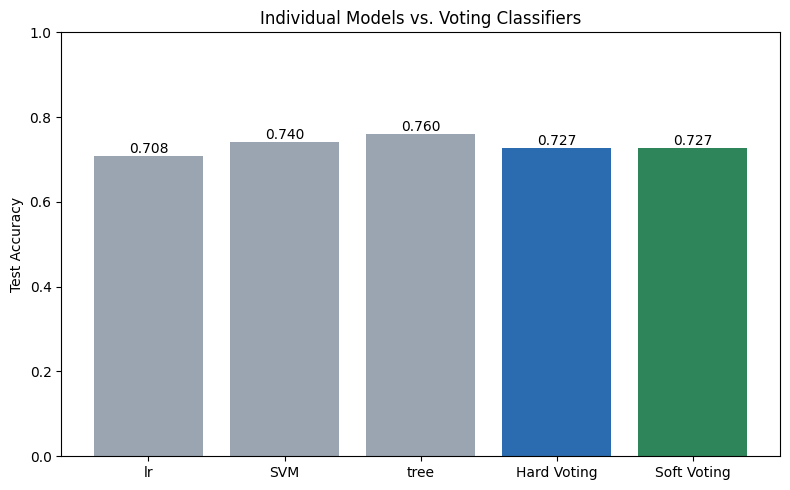

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

## collecting test accuracy for each individual model + both voting types
scores = {name: clf.score(XtestReady, yTest) for name, clf in vc.named_estimators_.items()}
scores['Hard Voting'] = accuracy_score(yTest, hard)
scores['Soft Voting'] = accuracy_score(yTest, soft)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(scores.keys(), scores.values(),
              color=['#9aa5b1'] * 3 + ['#2b6cb0', '#2f855a'])
ax.bar_label(bars, fmt='%.3f')          # prints the accuracy on top of each bar
ax.set_ylim(0, 1)
ax.set_ylabel('Test Accuracy')
ax.set_title('Individual Models vs. Voting Classifiers')
plt.tight_layout()
plt.show()

Now printing a visual representation of the confusion matrix to compare the inaccuracies of the voting types side by side.
This just allows me to see exactly what each voting type was getting wrong

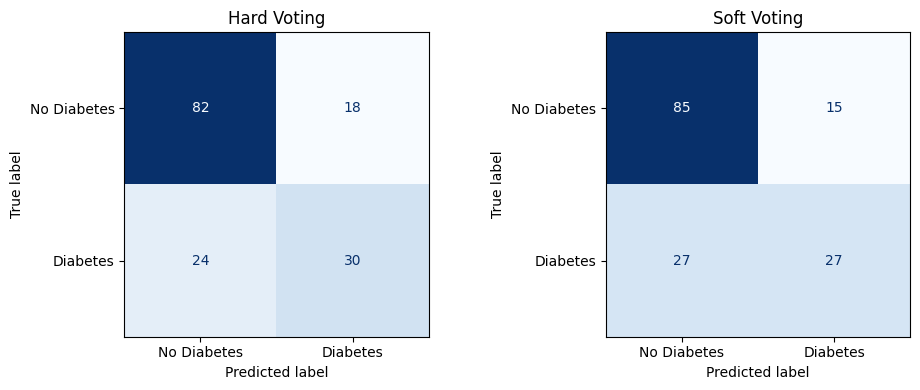

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, preds, title in zip(axes, [hard, soft], ['Hard Voting', 'Soft Voting']):
    ConfusionMatrixDisplay.from_predictions(
        yTest, preds,
        display_labels=['No Diabetes', 'Diabetes'],
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

We see in both plots some useful information
For the first set of box plots, we see the tree and SVM are slightly better in accuracy than the voting, but the logistic regression is worse than btoh voting models.
The models are the same in accuracy. But we know they are slightly different in what they got right from before.
The box plot tells us that the best parts of all the models are mixed and we get a somewhat even outcome. it's not anywhere near perfect but it is right in the middle

The confusion matrix tells us both models get a lot of false negatives. This is definitely worse than false positives as they doctor wouldn't know they have it without further testing. The true negative rate is pretty good but the true positive rate is a bit low. The false positives are really low.
The models are not perfect.


## Bagging Classifier Pipeline
Defining the bagging classifier pipeline with the preprocessing pipeline from before
After, I fit the training set to the model

In [37]:
from sklearn.ensemble import BaggingClassifier
baggingPipe = Pipeline([
    ('preprocess', clone(preprocessPipe)),
    ('bagClf', BaggingClassifier(DecisionTreeClassifier(),
        n_estimators=500,
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
        )
    )
])

baggingPipe.fit(Xtrain, yTrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['preg', 'plas', 'pres',
                                                   'skin', 'insu', 'mass',
                                                   'pedi', 'age']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('cat_encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [])])),
                ('bagClf',
                 BaggingClassifier(estimator=DecisionTreeClassifier(),
                                   n_estimators=500, n_jobs=-1, oob_score=True,
                                   random_state=42))])

getting the predictions and scores a well as a basic tree classifier to compare the results against

In [38]:
bagPred = baggingPipe.predict(Xtest)
bagScore = baggingPipe.score(Xtest, yTest)
bagClf = baggingPipe.named_steps['bagClf']
oobScore = bagClf.oob_score_

treePipe = Pipeline([
    ('preprocess', clone(preprocessPipe)),
    ('tree', DecisionTreeClassifier(random_state=42))
])
treePipe.fit(Xtrain, yTrain)
treeScore = treePipe.score(Xtest, yTest)

print('oob score: ', round(oobScore, 3))
print('Bagging acc', round(bagScore, 3))
print('Tree acc', round(treeScore, 3))


oob score:  0.762
Bagging acc 0.734
Tree acc 0.682


Results show Oob is the best, bagging is after and the regular tree is the worst

## Plotting the findings

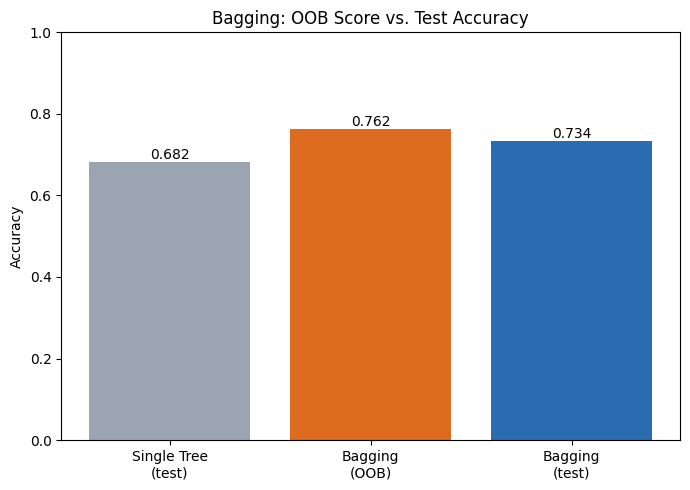

In [39]:
bagScores = {
    'Single Tree\n(test)': treeScore,
    'Bagging\n(OOB)': oobScore,
    'Bagging\n(test)': bagScore
}

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(list(bagScores.keys()), list(bagScores.values()),
              color=['#9aa5b1', '#dd6b20', '#2b6cb0'])
ax.bar_label(bars, fmt='%.3f')
ax.set_ylim(0, 1)
ax.set_ylabel('Accuracy')
ax.set_title('Bagging: OOB Score vs. Test Accuracy')
plt.tight_layout()
plt.show()

Plot shows the same results as before just visually

## Random Forest with feature subsetting
Importing the random forest model and making the pipeline
Fitting to the pipeline then predicting and scoring it. After, we print the results

In [40]:
from sklearn.ensemble import RandomForestClassifier

## defining the random forest pipeline
rfPipe = Pipeline([
    ('preprocess', clone(preprocessPipe)),
    ('RandomForest', RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',   # feature subsetting: each split only considers sqrt(8) ≈ 2-3 random features
            oob_score=True,        # optional, lets you compare with bagging's OOB score
            random_state=42,
            n_jobs=-1
        )
    )
])

rfPipe.fit(Xtrain, yTrain)

## evaluating test performance
rfClf = rfPipe.named_steps['RandomForest']
rfPred = rfPipe.predict(Xtest)
rfTestScore = rfPipe.score(Xtest, yTest)

print("Random Forest OOB score: ", round(rfClf.oob_score_, 3))
print("Random Forest test acc:  ", round(rfTestScore, 3))
print(classification_report(yTest, rfPred))

Random Forest OOB score:  0.762
Random Forest test acc:   0.734
              precision    recall  f1-score   support

           0       0.77      0.84      0.80       100
           1       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



## Feature Importance Plot
plotting the features by getting it via the pd.Series calla and entering the data as a parameter.
I also sort them at the end to organize the data and show it in a uniform manner
then making the box plot

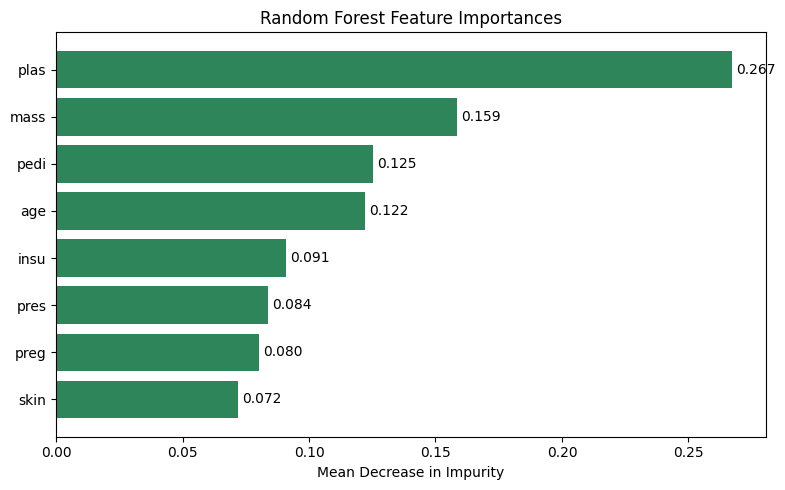

In [41]:
import pandas as pd

importances = pd.Series(rfClf.feature_importances_, index=numCols).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(importances.index, importances.values, color='#2f855a')
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set_xlabel('Mean Decrease in Impurity')
ax.set_title('Random Forest Feature Importances')
plt.tight_layout()
plt.show()

This shows that the plasma glucose levels are the most important predictor by far with BMI and pedigree being the second most
Age is another and the other below that are somewhat equally important while not being useless.
This tells us all features have importance, but some are more telling of diabetes than other (atleast to the model)

## Ada Boost Classifier

Creating the ada boost clf pipeline after importing and then fitting the model with the data
After, we get the columns names, score the accuracy and print the results as well as a classification report

In [42]:
from sklearn.ensemble import AdaBoostClassifier

## defining the AdaBoost pipeline
adaPipe = Pipeline([
    ('preprocess', clone(preprocessPipe)),
    ('AdaBoost', AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),  # decision stump: one split
            n_estimators=200,
            learning_rate=0.5,
            random_state=42
        )
    )
])

adaPipe.fit(Xtrain, yTrain)

## final training vs. test performance
adaClf = adaPipe.named_steps['AdaBoost']
adaTrainScore = adaPipe.score(Xtrain, yTrain)
adaTestScore = adaPipe.score(Xtest, yTest)

print("AdaBoost train acc:", round(adaTrainScore, 3))
print("AdaBoost test acc: ", round(adaTestScore, 3))
print(classification_report(yTest, adaPipe.predict(Xtest)))

AdaBoost train acc: 0.808
AdaBoost test acc:  0.734
              precision    recall  f1-score   support

           0       0.77      0.85      0.81       100
           1       0.65      0.52      0.58        54

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.69       154
weighted avg       0.73      0.73      0.73       154



## Plotting the Data
getting the column names for the plot, transforming the data so we can call on it later without the pipeline
calling the staged_score method on the classifier to get the ensemble scoreafter each iteration of boosting.
We then get the amount of rounds by using the trainStaged value from before.
After, we make the plot and plot the data

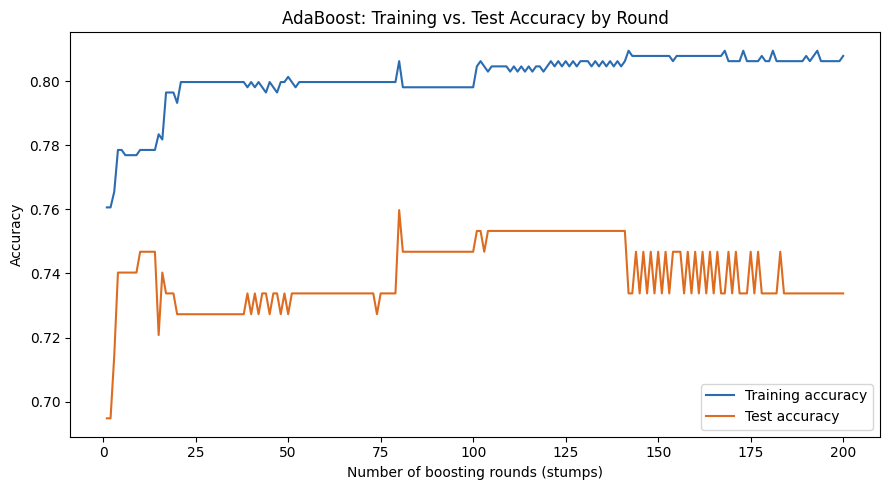

In [43]:
prep = adaPipe.named_steps['preprocess']
XtrainAda = prep.transform(Xtrain)
XtestAda = prep.transform(Xtest)

##getting the accuracy of the data after every iteration
trainStaged = list(adaClf.staged_score(XtrainAda, yTrain))
testStaged = list(adaClf.staged_score(XtestAda, yTest))
rounds = range(1, len(trainStaged) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rounds, trainStaged, label='Training accuracy', color='#2b6cb0')
ax.plot(rounds, testStaged, label='Test accuracy', color='#dd6b20')
ax.set_xlabel('Number of boosting rounds (stumps)')
ax.set_ylabel('Accuracy')
ax.set_title('AdaBoost: Training vs. Test Accuracy by Round')
ax.legend()
plt.tight_layout()
plt.show()

The results show us the results of the training data vs the test data.
The training accuracy climbs steadily and mostly balanaces out around 25 while still having a few spikes and a little average increase around 110
The testing score is much different. Not only is it worse, it also have much heavier spikes and is just generally inconsistent
It would be easy to say 80 rounds is best but the early hundreds are also fairly consistent for both